In [1]:
# 도구 불러오기
import cv2 # 이미지 읽기, 색공간 변환
import numpy as np # 이미지 픽셀을 숫자로 계산
import pandas as pd # 분석 결과를 표로 보기
import matplotlib.pyplot as plt # 이미지와 그래프 표시
import json # 분석 결과를 json 파일로 저장

from pathlib import Path # 이미지 파일 경로를 쉽게 다루기 위해 Pathlib 사용

In [2]:
# 이미지 경로 저장하기
reference_path = Path("images/reference/reference_1.png") 
target_path = Path(
    "images/target/target_1.png"
)
#Path는 파일 경로를 Python에서 다루기 쉽게 만들어주는 객체

In [3]:
#이미지 읽기

reference_bgr = cv2.imread(
    str(reference_path),
    cv2.IMREAD_COLOR
)

target_bgr = cv2.imread(
    str(target_path),
    cv2.IMREAD_COLOR
)
# cv2.imread()는 이미지 파일을 읽는 함수
# OpenCV는 이미지를 기본적으로 BGR순서로 읽는다 (BLUE / GREEN / RED)
# Matplotlib은 RGB순서를 사용
# 화면에 올바른 색으로 표시하려면 변환해야한다

reference_rgb = cv2.cvtColor(
    reference_bgr,
    cv2.COLOR_BGR2RGB
)

target_rgb = cv2.cvtColor(
    target_bgr,
    cv2.COLOR_BGR2RGB
)


In [4]:
## 이미지 읽기 오류 확인

if reference_bgr is None:
    raise FileNotFoundError(
        f"Reference 이미지를 읽을 수 없습니다: {reference_path}"
    )

if target_bgr is None:
    raise FileNotFoundError(
        f"Target 이미지를 읽을 수 없습니다: {target_path}"
    )

In [5]:
# 이미지 크기와 구조 확인하기
# (높이, 너비, 색상 수)
print("Reference shape:", reference_rgb.shape)
print("Target shape:", target_rgb.shape)

Reference shape: (2160, 3840, 3)
Target shape: (2160, 3840, 3)


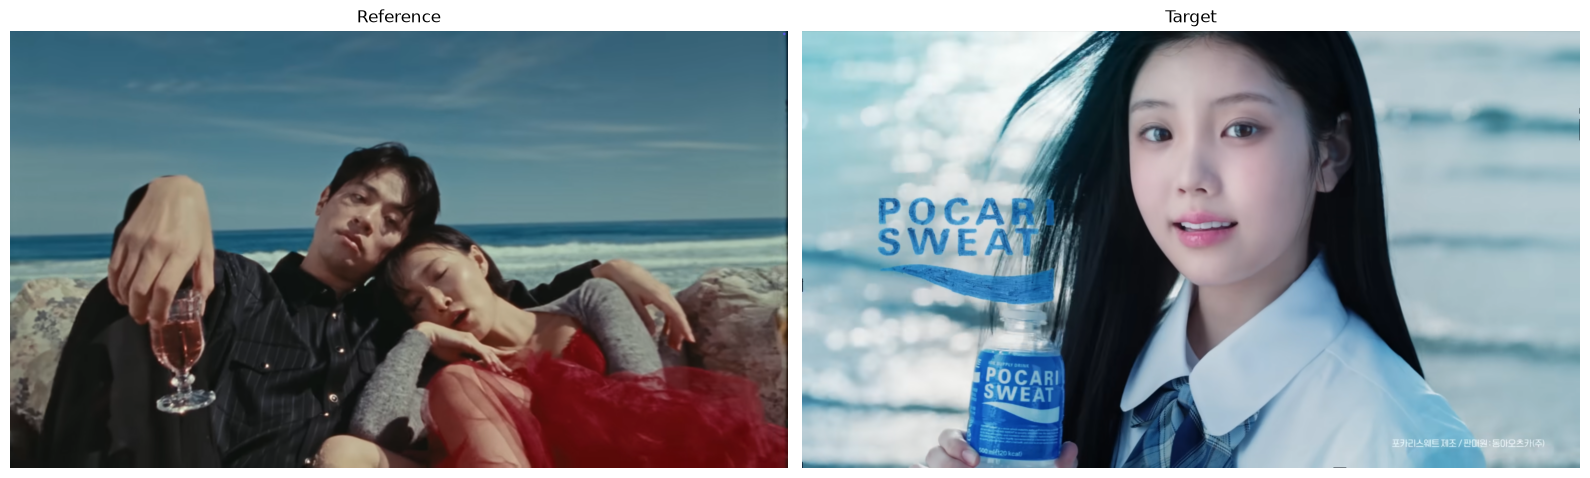

In [6]:
# 이미지 나란히 표시하기

fig,axes = plt.subplots(
    1,
    2,
    figsize=(16,6)
)

axes[0].imshow(reference_rgb)
axes[0].set_title("Reference")
axes[0].axis("off")

axes[1].imshow(target_rgb)
axes[1].set_title("Target")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Lab 색공간으로 변환하기
# L : 밝기 / A : 초록-빨강 / B : 파랑 - 노랑
reference_lab = cv2.cvtColor(
    reference_rgb,
    cv2.COLOR_RGB2LAB
)

target_lab = cv2.cvtColor(
    target_rgb,
    cv2.COLOR_RGB2LAB
)

In [ ]:
reference_l = reference_lab[:,:,0]
target_l = target_lab[:,:,0]

reference_lightness = (
    reference_l.astype(np.float32) / 255*100
)

target_lightness = (
    target_l.astype(np.float32) / 255 * 100
)

# astype(np.float32)는 배열을 소수 계산이 가능한 NumPy 자료형으로 바꾸는 것

In [10]:
# 기본 밝기 통계 계산하기

def describe_lightness(lightness):
    return{
        "mean": float(lightness.mean()), #평균 밝기
        "std": float(lightness.std()), #평균 분산정도
        "min": float(lightness.min()), #가장 어두운값
        "max": float(lightness.max()), #가장 밝은 값
        "p01": float(np.percentile(lightness, 1)), # 하위1%지점
        "p05": float(np.percentile(lightness,5)), 
        "p50": float(np.percentile(lightness, 50)), # 중앙값
        "p95": float(np.percentile(lightness,95)),
        "p99": float(np.percentile(lightness,99)) # 상위1% 지점
    }

In [12]:
reference_stats = describe_lightness(reference_lightness)
target_stats = describe_lightness(target_lightness)

print("Reference")
print(reference_stats)

print("target")
print(target_stats)

Reference
{'mean': 38.1560173034668, 'std': 18.732465744018555, 'min': 0.0, 'max': 100.0, 'p01': 4.705882549285889, 'p05': 6.274510383605957, 'p50': 41.960784912109375, 'p95': 65.09803771972656, 'p99': 73.33333587646484}
target
{'mean': 61.118404388427734, 'std': 27.923236846923828, 'min': 0.0, 'max': 99.60784149169922, 'p01': 2.745098114013672, 'p05': 3.529412031173706, 'p50': 74.11764526367188, 'p95': 90.98039245605469, 'p99': 96.47058868408203}


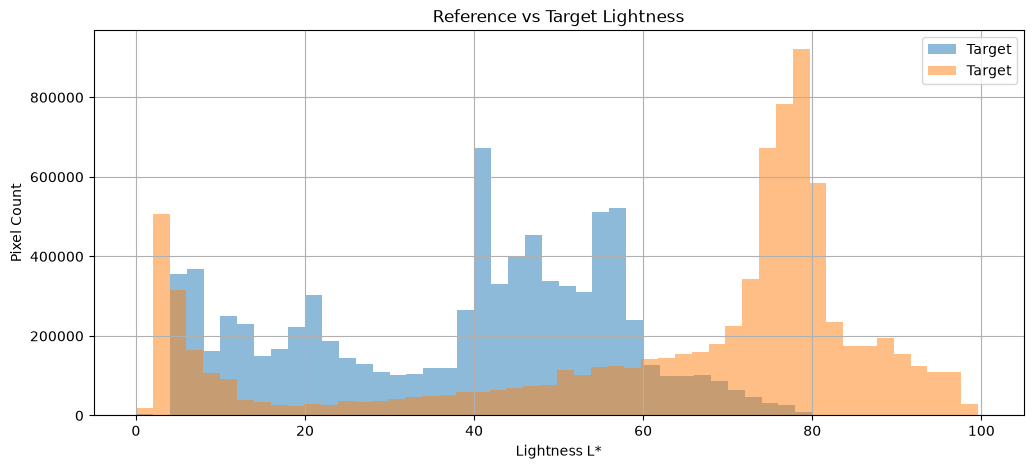

In [13]:
# 밝기 히스토그램 비교하기
plt.figure(figsize=(12,5))

plt.hist(
    reference_lightness.flatten(),
    bins=50,
    alpha=0.5,
    label="Target"
)

plt.hist(
    target_lightness.flatten(),
    bins=50,
    alpha=0.5,
    label="Target"
)

plt.xlabel("Lightness L*")
plt.ylabel("Pixel Count")
plt.title("Reference vs Target Lightness")
plt.legend()
plt.grid()
plt.show()



In [ ]:
# Shadow/Midtone/Highlight 나누기

def make_tonal_masks(lightness):
    shadow_threshold, highlight_threshold = np.percentile(
        lightness,
        [20,80]
    )

    shadow_mask = lightness <=shadow_threshold
    
    midtone_mask = (
        (lightness>shadow_threshold)&
        (lightness<highlight_threshold)
    )

    highlight_mask = lightness >= highlight_threshold

    return(
        shadow_mask, 
        midtone_mask,
        highlight_mask,
        shadow_threshold, #shadow 기준값
        highlight_threshold #highlight 기준값
    )


In [ ]:
# Reference와 Target에 각각 적용
make_tonal_masks(reference_lightness)
make_tonal_masks(target_lightness)

In [ ]:
# 영역별 통계 계산하기
def analyze_region(lightness, mask):
    selected = lightness[mask]

    return{
        "pixel_ratio": float(len(selected)/lightness.size)
        
    }

Shadow RGB: [29.94525558 25.55418228 23.9708525 ]
Midtone RGB: [ 83.90338497  92.58043935 101.74939304]
Highlight RGB: [137.01441367 150.21981534 143.82143415]


In [15]:
# HSV로 채도 분석

hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)

saturation = hsv [:,:,1].astype(np.float32) / 255*100

# 채도는 함수로 계산합니다
def get_mean_value(values, mask):
    selected = values[mask]

    if len(selected) == 0:
        return np.nan

    return selected.mean()

In [16]:
shadow_saturation = get_mean_value(
    saturation,
    shadow_mask
)

midtone_saturation = get_mean_value(
    saturation,
    midtone_mask
)

highlight_saturation = get_mean_value(
    saturation,
    highlight_mask
)

print("Shadow 채도:", shadow_saturation)
print("Midtone 채도:", midtone_saturation)
print("Highlight 채도:", highlight_saturation)

Shadow 채도: 20.016401
Midtone 채도: 46.874958
Highlight 채도: 23.256813


In [ ]:
# RMS 대비
# 값이 높을수록 전체적인 밝기 차이가 큽니다
rms_contrast = lightness.std()

print("RMS대비:", rms_contrast)

RMS대비: 18.732466


In [18]:
# Percentile 대비
p05, p95 = np.percentile(lightness, [5,95])

precentile_contrast = p95 - p05

print("precentile대비:", precentile_contrast)

precentile대비: 58.823527336120605


In [ ]:
# Highlight와 Shadow 차이

highlight_mean = highlight_lightness.mean()
shadow_mean = shadow_lightness.mean()

highlight_shadow_gap = highlight_mean - shadow_mean

print("Highlight와 Shadow 차이 : ", highlight_shadow_gap)

# 0~25 : 낮은 대비
# 25~50 : 중간 대비
# 50 이상 : 높은 대비
# 절대적인 규칙은 아님

Highlight와 Shadow 차이 :  51.363583


In [ ]:
# 결과를 표로 정리하기

region_data = [
    {
        "region" : "shadow",
        "ratio" : shadow_ratio,
        "mean_lightness" : shadow_lightness.mean(),
        "std_lightness" : shadow_lightness.std(),
        "mean_r": shadow_rgb[0],
        "mean_g": shadow_rgb[1],
        "mean_b": shadow_rgb[2],
        "mean_saturation": shadow_saturation,
    },
    {
            "region" : "midtone",
            "ratio" : midtone_ratio,
            "mean_lightness" : midtone_lightness.mean(),
            "std_lightness" : midtone_lightness.std(),
            "mean_r": midtone_rgb[0],
            "mean_g": midtone_rgb[1],
            "mean_b": midtone_rgb[2],
            "mean_saturation": midtone_saturation,
    },
    {
            "region" : "highlight",
            "ratio" : highlight_ratio,
            "mean_lightness" : highlight_lightness.mean(),
            "std_lightness" : highlight_lightness.std(),
            "mean_r": highlight_rgb[0],
            "mean_g": highlight_rgb[1],
            "mean_b": highlight_rgb[2],
            "mean_saturation": highlight_saturation,
    },
]

region_df = pd.DataFrame(region_data)

region_df # 영역별 분석 결과를 표로 볼 수 잇다.

,region,ratio,mean_lightness,std_lightness,mean_r,mean_g,mean_b,mean_saturation
0,shadow,0.203532,9.835151,3.976390,29.945256,25.554182,23.970852,20.016401
1,midtone,0.595904,40.073517,10.735316,83.903385,92.580439,101.749393,46.874958
2,highlight,0.200564,61.198734,5.941436,137.014414,150.219815,143.821434,23.256813


In [21]:
# JSON으로 저장하기
analysis_result = {
    "image": str(image_path),
    "thresholds":{
        "shadow": float(shadow_threshold),
        "highlight": float(highlight_threshold),
    },
    "contrast": {
        "rms" : float(rms_contrast),
        "percentile": float(precentile_contrast),
        "highlight_shadow_gap": float(highlight_shadow_gap),
    },
    "regions": region_data,
}

In [23]:
def convert_numpy_types(value):
    if isinstance(value, dict):
        return {
            key: convert_numpy_types(item)
            for key, item in value.items()
        }

    if isinstance(value, list):
        return [
            convert_numpy_types(item)
            for item in value
        ]

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        return float(value)

    if isinstance(value, np.ndarray):
        return value.tolist()

    return value

In [25]:
analysis_result = convert_numpy_types(analysis_result)

In [26]:
result_path = Path("results/reference_1_analysis.json")

with result_path.open("w", encoding="utf-8") as f:
    json.dump(
        analysis_result,
        f,
        ensure_ascii=False,
        indent=2,
    )

print("저장완료:", result_path)

저장완료: results/reference_1_analysis.json
